In [4]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
cities = gpd.read_file("data/puget_sound_cities.geojson")
study = cities[cities["NAME"].isin(["Federal Way", "Seattle", "Tacoma"])].to_crs(2927)
study[["NAME", "geometry"]]

,NAME,geometry
6,Tacoma,"MULTIPOLYGON (((1140103.895 697430.631, 114031..."
8,Federal Way,"POLYGON ((1163482.108 731779.537, 1165378.068 ..."
12,Seattle,"POLYGON ((1157572.951 859053.061, 1157615.802 ..."


In [6]:
bbox = tuple(study.to_crs(4326).total_bounds)

osm = gpd.read_file("data/osm/gis_osm_buildings_a_free_1.shp", bbox=bbox)
print(len(osm), "OSM buildings in the box")
osm.head()

543327 OSM buildings in the box


,osm_id,code,fclass,name,type,geometry
0,4712871,1500,building,Pacific Tower,office,"POLYGON ((-122.31653 47.59265, -122.31653 47.5..."
1,4712941,1500,building,Fire Station 30,fire_station,"POLYGON ((-122.295 47.57548, -122.295 47.57569..."
2,4725281,1500,building,King Street Station,train_station,"POLYGON ((-122.33024 47.59818, -122.33023 47.5..."
3,5170208,1500,building,Tacoma Mall,NaN,"POLYGON ((-122.47238 47.2159, -122.47238 47.21..."
4,5876771,1500,building,The Outlet Collection Seattle,NaN,"POLYGON ((-122.24899 47.29891, -122.2485 47.29..."


In [7]:
ms = gpd.read_file("data/Washington.geojson", bbox=bbox)
print(len(ms), "Microsoft buildings in the box")

483656 Microsoft buildings in the box


In [8]:
def tag_city(buildings):
    points = buildings.to_crs(2927)
    points["geometry"] = points.representative_point()
    return gpd.sjoin(points[["geometry"]], study[["NAME", "geometry"]], predicate="within").drop(columns="index_right")

osm_pts = tag_city(osm)
ms_pts = tag_city(ms)
print(len(osm_pts), "OSM buildings inside the three cities")
print(len(ms_pts), "Microsoft buildings inside the three cities")

336617 OSM buildings inside the three cities
292958 Microsoft buildings inside the three cities


In [9]:
comp = pd.DataFrame({
    "osm_buildings": osm_pts.groupby("NAME").size(),
    "ms_buildings": ms_pts.groupby("NAME").size(),
})
comp["completeness_pct"] = (comp["osm_buildings"] / comp["ms_buildings"] * 100).round(1)
comp = comp.sort_values("completeness_pct")
comp

,osm_buildings,ms_buildings,completeness_pct
NAME,,,
Federal Way,26311,25565,102.9
Seattle,215147,186393,115.4
Tacoma,95159,81000,117.5


In [10]:
import numpy as np
from shapely.geometry import box

size = 1500
xmin, ymin, xmax, ymax = study.total_bounds

squares = [box(x, y, x + size, y + size)
           for x in np.arange(xmin, xmax, size)
           for y in np.arange(ymin, ymax, size)]

grid = gpd.GeoDataFrame(geometry=squares, crs=study.crs)
grid = gpd.sjoin(grid, study[["NAME", "geometry"]], predicate="intersects").drop(columns="index_right")
grid = grid[~grid.index.duplicated()].reset_index(drop=True)
grid["cell_id"] = grid.index
print(len(grid), "grid cells over the three cities")

3102 grid cells over the three cities


In [11]:
def count_per_cell(points):
    joined = gpd.sjoin(points[["geometry"]], grid[["cell_id", "geometry"]], predicate="within")
    return joined.groupby("cell_id").size()

grid["osm"] = grid["cell_id"].map(count_per_cell(osm_pts)).fillna(0)
grid["ms"] = grid["cell_id"].map(count_per_cell(ms_pts)).fillna(0)

grid["completeness"] = (grid["osm"] / grid["ms"] * 100).round(1)
grid_valid = grid[grid["ms"] >= 10]
print(len(grid_valid), "cells with at least 10 Microsoft buildings")
grid_valid.groupby("NAME")["completeness"].describe().round(1)

1923 cells with at least 10 Microsoft buildings


,count,mean,std,min,25%,50%,75%,max
NAME,,,,,,,,
Federal Way,269.0,106.3,21.9,70.0,99.5,101.5,107.6,296.0
Seattle,1067.0,117.8,24.0,0.0,107.6,114.2,121.0,416.7
Tacoma,587.0,119.1,22.2,20.0,106.6,117.4,125.4,330.8


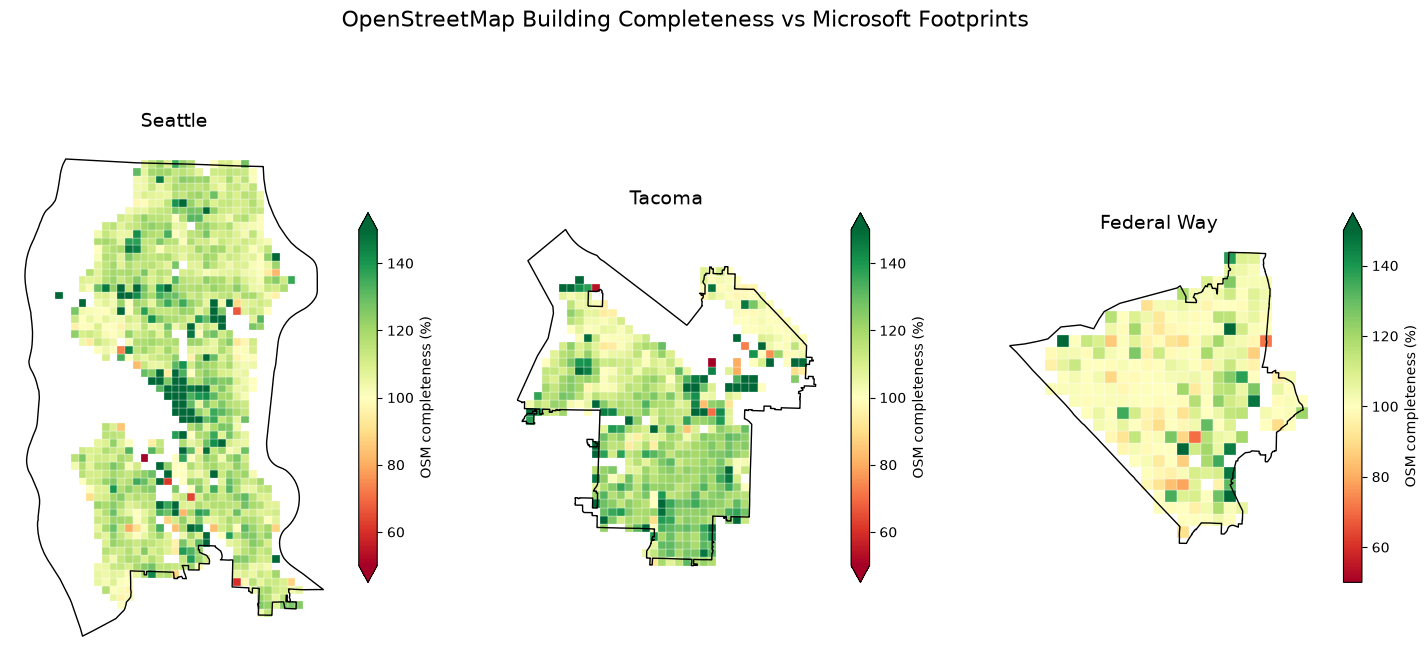

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, city in zip(axes, ["Seattle", "Tacoma", "Federal Way"]):
    cells = grid_valid[grid_valid["NAME"] == city]
    cells.plot(ax=ax, column="completeness", cmap="RdYlGn", vmin=50, vmax=150,
               edgecolor="white", linewidth=0.2, legend=True,
               legend_kwds={"label": "OSM completeness (%)", "shrink": 0.6})
    study[study["NAME"] == city].boundary.plot(ax=ax, color="black", linewidth=1)
    ax.set_title(city, fontsize=14)
    ax.set_axis_off()

fig.suptitle("OpenStreetMap Building Completeness vs Microsoft Footprints", fontsize=16)
plt.savefig("completeness_map.png", dpi=150, bbox_inches="tight")

In [13]:
gaps = grid_valid[grid_valid["completeness"] < 75]
print(len(gaps), "squares below 75% complete")
print(gaps.groupby("NAME").size())

gaps.sort_values("completeness")[["NAME", "osm", "ms", "completeness"]].head(10)

12 squares below 75% complete
NAME
Federal Way    2
Seattle        6
Tacoma         4
dtype: int64


,NAME,osm,ms,completeness
1821,Seattle,0.0,10.0,0.0
759,Tacoma,2.0,10.0,20.0
201,Tacoma,7.0,13.0,53.8
2673,Seattle,6.0,10.0,60.0
2042,Seattle,8.0,13.0,61.5
2268,Seattle,7.0,11.0,63.6
2708,Seattle,8.0,12.0,66.7
2093,Federal Way,7.0,10.0,70.0
753,Tacoma,7.0,10.0,70.0
2543,Federal Way,10.0,14.0,71.4


In [14]:
gaps.to_crs(4326).explore(column="completeness", cmap="Reds_r", tiles="OpenStreetMap")